# DenseNet121 + CBAM -- Pneumonia Detection
### Companion model for ensemble with EfficientNetB3
Cell 8 in pneumonia_notebook.ipynb for ensemble evaluation.

In [1]:
# ==================================================
# CELL 1 - SETUP & GPU CHECK
# Run this first, always
# ==================================================
import os, sys, cv2, shutil, random, time, json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, Model, regularizers
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.callbacks import (EarlyStopping, ReduceLROnPlateau, Callback)
from tensorflow.keras.metrics import AUC, Precision, Recall
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, roc_auc_score, recall_score,
                              precision_score, f1_score, confusion_matrix, roc_curve)
from IPython.display import display
import ipywidgets as widgets

# Configure GPU environment for 6GB VRAM
os.environ['TF_FORCE_GPU_ALLOW_GROWTH'] = 'true'
os.environ['TF_CPP_MIN_LOG_LEVEL']      = '2'

BASE_DIR   = r'C:\pneu\chest_xray'
OUTPUT_DIR = r'C:\pneu\outputs'
TRAIN_DIR  = os.path.join(BASE_DIR, 'train')
VAL_DIR    = os.path.join(BASE_DIR, 'val')
TEST_DIR   = os.path.join(BASE_DIR, 'test')
os.makedirs(os.path.join(OUTPUT_DIR, 'models'), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, 'plots'),  exist_ok=True)

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f'GPU : {gpus[0].name}  |  TF {tf.__version__} (GPU Acceleration Enabled)')
    except RuntimeError as e:
        print('Memory growth runtime error:', e)
else:
    print('WARNING: No GPU detected')

random.seed(42); np.random.seed(42); tf.random.set_seed(42)
IMG_SIZE = (260, 260)
# Batch size 8 is optimized for 6GB VRAM stability with deep feature maps
BATCH    = 8

def _scrub_logs(logs):
    if not logs: return logs
    for k in list(logs.keys()):
        v = logs[k]
        try:
            if hasattr(v, 'numpy'):         logs[k] = float(v.numpy())
            elif isinstance(v, np.ndarray): logs[k] = float(v.flat[0])
            else:                           logs[k] = float(v)
        except Exception: pass
    return logs

_orig_e = tf.keras.callbacks.CallbackList.on_epoch_end
def _patch_e(self, epoch, logs=None):
    return _orig_e(self, epoch, _scrub_logs(logs))
tf.keras.callbacks.CallbackList.on_epoch_end = _patch_e

_orig_b = tf.keras.callbacks.CallbackList.on_train_batch_end
def _patch_b(self, batch, logs=None):
    return _orig_b(self, batch, _scrub_logs(logs))
tf.keras.callbacks.CallbackList.on_train_batch_end = _patch_b

_orig_t = tf.keras.callbacks.CallbackList.on_test_batch_end
def _patch_t(self, batch, logs=None):
    return _orig_t(self, batch, _scrub_logs(logs))
tf.keras.callbacks.CallbackList.on_test_batch_end = _patch_t
print('Callbacks patched')

class PureCheckpoint(Callback):
    def __init__(self, filepath, monitor='val_auc', mode='max', verbose=1):
        super().__init__()
        self.filepath = filepath; self.monitor = monitor
        self.mode = mode; self.verbose = verbose
        self.best = -np.inf if mode == 'max' else np.inf
    def on_epoch_end(self, epoch, logs=None):
        logs    = logs or {}
        val = logs.get(self.monitor)
        if val is None:
            # Fallback search if metric name has suffix
            for k, v in logs.items():
                if self.monitor in k:
                    val = v; break
        current = float(val) if val is not None else -np.inf
        improved = (current > self.best) if self.mode == 'max' else (current < self.best)
        if improved:
            self.best = current
            self.model.save_weights(self.filepath)
            if self.verbose:
                print(f'\n  checkmark {self.monitor}={current:.4f} -- saved {os.path.basename(self.filepath)}')

class ProgressBar(Callback):
    def __init__(self, stage, total_epochs, steps):
        super().__init__()
        self.stage = stage; self.total_epochs = total_epochs
        self.steps = steps; self.best_auc = 0.0; self._t0 = None
        try:
            display(widgets.HTML(
                f"<b style='font-size:14px'>Stage {stage} Training</b>"
                f" -- {total_epochs} epochs | batch={BATCH} | 260x260"))
            self.epoch_bar = widgets.IntProgress(value=0, min=0, max=total_epochs,
                description='Epoch 0:', bar_style='info', layout=widgets.Layout(width='55%'))
            self.epoch_lbl = widgets.Label(value='starting...')
            self.best_lbl  = widgets.Label(value='')
            self.batch_bar = widgets.IntProgress(value=0, min=0, max=steps,
                description='Batch:', bar_style='', layout=widgets.Layout(width='55%'))
            self.batch_lbl = widgets.Label(value='')
            display(widgets.HBox([self.epoch_bar, self.epoch_lbl]))
            display(self.best_lbl)
            display(widgets.HBox([self.batch_bar, self.batch_lbl]))
            self.use_widgets = True
        except Exception:
            self.use_widgets = False

    def on_epoch_begin(self, epoch, logs=None):
        self._t0 = time.time()
        if self.use_widgets:
            self.epoch_bar.description = f'Epoch {epoch+1}:'
            self.batch_bar.value = 0

    def on_train_batch_end(self, batch, logs=None):
        logs = logs or {}
        if self.use_widgets:
            self.batch_bar.value = batch + 1
            self.batch_lbl.value = (f"loss={float(logs.get('loss',0)):.4f}  "
                                    f"acc={float(logs.get('accuracy',0)):.4f}")

    def on_epoch_end(self, epoch, logs=None):
        elapsed = time.time() - self._t0; logs = logs or {}
        vauc=float(logs.get('val_auc',0)); vacc=float(logs.get('val_accuracy',0))
        vloss=float(logs.get('val_loss',0)); vrec=float(logs.get('val_recall',0))
        if self.use_widgets:
            self.epoch_bar.value = epoch + 1
            self.epoch_lbl.value = (f"val_acc={vacc*100:.2f}%  val_auc={vauc*100:.2f}%  "
                                    f"val_loss={vloss:.4f}  val_rec={vrec*100:.2f}%  ({elapsed:.0f}s)")
            if vauc > self.best_auc:
                self.best_auc = vauc
                self.best_lbl.value = f"Best -> val_auc={vauc*100:.2f}%  val_acc={vacc*100:.2f}%"
                self.epoch_bar.bar_style = 'success'
            else:
                self.epoch_bar.bar_style = 'info'
            if epoch + 1 == self.total_epochs:
                self.epoch_bar.bar_style = 'success'; self.batch_bar.bar_style = 'success'
        else:
            print(f"Epoch {epoch+1}/{self.total_epochs} ({elapsed:.0f}s) - loss: {float(logs.get('loss',0)):.4f} - acc: {vacc*100:.2f}% - val_auc: {vauc*100:.2f}%")

print(f'IMG_SIZE={IMG_SIZE}  BATCH={BATCH}')
print('CELL 1 DONE -- proceed to Cell 2')


GPU : /physical_device:GPU:0  |  TF 2.10.0
Callbacks patched
IMG_SIZE=(260, 260)  BATCH=16
CELL 1 DONE -- proceed to Cell 2


In [2]:
# ==================================================
# CELL 2 - DATASET CHECK
# Just prints sizes, no file moving
# ==================================================
print('Dataset split:')
for s, path in [('Train', TRAIN_DIR), ('Val', VAL_DIR), ('Test', TEST_DIR)]:
    n = len(os.listdir(os.path.join(path, 'NORMAL')))
    p = len(os.listdir(os.path.join(path, 'PNEUMONIA')))
    ratio = p / n
    flag  = '  IMBALANCED' if ratio > 2 else '  OK'
    print(f'  {s:5}: {n+p:4}  (NORMAL={n}  PNEUMONIA={p}  ratio={ratio:.1f}){flag}')
print('CELL 2 DONE -- proceed to Cell 3')


Dataset split:
  Train: 4433  (NORMAL=1049  PNEUMONIA=3384  ratio=3.2)  IMBALANCED
  Val  :  802  (NORMAL=301  PNEUMONIA=501  ratio=1.7)  OK
  Test :  624  (NORMAL=234  PNEUMONIA=390  ratio=1.7)  OK
CELL 2 DONE -- proceed to Cell 3


In [3]:
# ==================================================
# CELL 3 - CLAHE + GENERATORS + MIXUP + CLASS WEIGHTS
# ==================================================
def apply_clahe(image):
    img  = image.astype(np.uint8)
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    cl   = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8)).apply(gray)
    return cv2.merge([cl, cl, cl]).astype(np.float32) / 255.0

# Stronger augmentation for DenseNet
train_gen = ImageDataGenerator(
    preprocessing_function=apply_clahe,
    rotation_range=20,
    width_shift_range=0.15, height_shift_range=0.15,
    zoom_range=0.20, horizontal_flip=True,
    shear_range=0.12, brightness_range=[0.70, 1.30],
    fill_mode='nearest'
).flow_from_directory(TRAIN_DIR, target_size=IMG_SIZE, batch_size=BATCH,
    class_mode='binary', color_mode='rgb', shuffle=True, seed=42)

val_gen = ImageDataGenerator(preprocessing_function=apply_clahe
).flow_from_directory(VAL_DIR, target_size=IMG_SIZE, batch_size=BATCH,
    class_mode='binary', color_mode='rgb', shuffle=False)

test_gen = ImageDataGenerator(preprocessing_function=apply_clahe
).flow_from_directory(TEST_DIR, target_size=IMG_SIZE, batch_size=BATCH,
    class_mode='binary', color_mode='rgb', shuffle=False)

STEPS     = train_gen.samples // BATCH
VAL_STEPS = val_gen.samples   // BATCH

# Mixup: blends two images for Stage 2 & 3
def mixup_generator(gen, alpha=0.20):
    while True:
        x1, y1 = next(gen)
        x2, y2 = next(gen)
        lam = np.random.beta(alpha, alpha)
        yield lam * x1 + (1 - lam) * x2, lam * y1 + (1 - lam) * y2

train_gen_mix = mixup_generator(train_gen, alpha=0.20)

cw = compute_class_weight('balanced', classes=np.array([0, 1]), y=train_gen.classes)
CLASS_WEIGHT = {0: cw[0], 1: cw[1]}

print(f'Steps/epoch  : {STEPS}  |  Val steps : {VAL_STEPS}')
print(f'Class weights: NORMAL={CLASS_WEIGHT[0]:.2f}  PNEUMONIA={CLASS_WEIGHT[1]:.2f}')
print('CELL 3 DONE -- proceed to Cell 4')


Found 4432 images belonging to 2 classes.
Found 800 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
Steps/epoch  : 277  |  Val steps : 50
Class weights: NORMAL=2.11  PNEUMONIA=0.66
CELL 3 DONE -- proceed to Cell 4


In [4]:
# ==================================================
# CELL 4 - BUILD DenseNet121 + CBAM + Label Smoothing
# ==================================================
L2 = 1e-4

# Built-in robust BinaryCrossentropy with label smoothing (prevents shape broadcasting bugs)
def get_loss(smoothing=0.10):
    return tf.keras.losses.BinaryCrossentropy(label_smoothing=smoothing)

def channel_attention(x, ratio=8):
    ch = x.shape[-1]
    d1 = layers.Dense(ch//ratio, activation='relu',
                       kernel_regularizer=regularizers.l2(L2))
    d2 = layers.Dense(ch, kernel_regularizer=regularizers.l2(L2))
    avg = layers.GlobalAveragePooling2D()(x)
    mx  = layers.GlobalMaxPooling2D()(x)
    out = layers.Activation('sigmoid')(layers.Add()([d2(d1(avg)), d2(d1(mx))]))
    return layers.Multiply()([x, layers.Reshape((1, 1, ch))(out)])

def spatial_attention(x):
    avg = layers.Lambda(lambda t: tf.reduce_mean(t, axis=-1, keepdims=True))(x)
    mx  = layers.Lambda(lambda t: tf.reduce_max(t,  axis=-1, keepdims=True))(x)
    out = layers.Conv2D(1, 7, padding='same', activation='sigmoid')(
          layers.Concatenate(axis=-1)([avg, mx]))
    return layers.Multiply()([x, out])

def build_densenet():
    inp  = layers.Input(shape=(*IMG_SIZE, 3))
    base = DenseNet121(include_top=False, weights='imagenet', input_tensor=inp)
    base.trainable = False
    x = channel_attention(base.output)
    x = spatial_attention(x)
    x = layers.GlobalAveragePooling2D()(x)
    for units, drop in [(512, 0.50), (256, 0.40)]:
        x = layers.Dense(units, kernel_regularizer=regularizers.l2(L2))(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.Dropout(drop)(x)
    out = layers.Dense(1, activation='sigmoid', dtype='float32',
                       kernel_regularizer=regularizers.l2(L2))(x)
    return Model(inp, out, name='DenseNet121_CBAM'), base

dn_model, dn_base = build_densenet()
print(f'Total params : {dn_model.count_params():,}')
print('CELL 4 DONE -- proceed to Cell 5')


Total params : 7,960,356
CELL 4 DONE -- proceed to Cell 5


In [5]:
# ==================================================
# CELL 5 - STAGE 1: Head only | Backbone Frozen
# Saves: dn_stage1.h5
# ==================================================
print('='*55)
print('DN STAGE 1 | backbone FROZEN | lr=1e-3')
print('='*55)

dn_base.trainable = False
dn_model.compile(optimizer=Adam(1e-3), loss=get_loss(0.10),
              metrics=['accuracy', AUC(name='auc'),
                       Precision(name='precision'), Recall(name='recall')])

# Stage 1 uses standard aug + class_weight (mixup continuous labels conflict with class_weight)
h1 = dn_model.fit(
    train_gen,
    epochs=15, steps_per_epoch=STEPS,
    validation_data=val_gen, validation_steps=VAL_STEPS,
    class_weight=CLASS_WEIGHT,
    callbacks=[
        PureCheckpoint(os.path.join(OUTPUT_DIR,'models','dn_stage1.h5'),
                       monitor='val_auc', mode='max', verbose=1),
        EarlyStopping(monitor='val_auc', patience=8,
                      restore_best_weights=True, mode='max', verbose=0),
        ReduceLROnPlateau(monitor='val_loss', factor=0.3,
                          patience=4, min_lr=1e-10, verbose=0),
        ProgressBar(1, 15, STEPS)
    ], verbose=0)

with open(os.path.join(OUTPUT_DIR,'models','dn_history_s1.json'),'w') as f:
    json.dump({k:[float(v) for v in vals] for k,vals in h1.history.items()}, f, indent=2)
print(f'DN Stage 1:  acc={max(h1.history["val_accuracy"])*100:.2f}%   auc={max(h1.history["val_auc"])*100:.2f}%')
print('Saved: dn_stage1.h5')
print('CELL 5 DONE -- proceed to Cell 6')


DN STAGE 1 | backbone FROZEN | lr=1e-3 | ~29 min


HTML(value="<b style='font-size:14px'>Stage 1 Training</b> -- 15 epochs | batch=16 | 260x260")

Label(value='')


  checkmark val_auc=0.9804 -- saved dn_stage1.h5

  checkmark val_auc=0.9879 -- saved dn_stage1.h5

  checkmark val_auc=0.9919 -- saved dn_stage1.h5
DN Stage 1:  acc=93.37%   auc=99.19%
Saved: dn_stage1.h5
CELL 5 DONE -- proceed to Cell 6


In [5]:
# ==================================================
# CELL 6 - STAGE 2: Top 50% unfrozen + Mixup
# Saves: dn_stage2.h5
# If interrupted: re-run Cell 1 then this cell
# ==================================================
s1_path = os.path.join(OUTPUT_DIR,'models','dn_stage1.h5')
if os.path.exists(s1_path):
    dn_model.load_weights(s1_path)
    print('Loaded weights from dn_stage1.h5')

print('='*55)
print('DN STAGE 2 | top 50% unfrozen, BN frozen | lr=1e-4')
print('='*55)

dn_base.trainable = True
cutoff = int(len(dn_base.layers) * 0.50)
for i, l in enumerate(dn_base.layers):
    if i < cutoff:
        l.trainable = False
    else:
        l.trainable = False if isinstance(l, tf.keras.layers.BatchNormalization) else True

unfrozen = sum(1 for l in dn_base.layers if l.trainable)
print(f'Unfrozen: {unfrozen}/{len(dn_base.layers)} backbone layers  (BN always frozen)')

dn_model.compile(optimizer=Adam(1e-4), loss=get_loss(0.0),
              metrics=['accuracy', AUC(name='auc'),
                       Precision(name='precision'), Recall(name='recall')])

# Stage 2 uses mixup for softer decision boundary
h2 = dn_model.fit(
    train_gen_mix,
    epochs=25, steps_per_epoch=STEPS,
    validation_data=val_gen, validation_steps=VAL_STEPS,
    callbacks=[
        PureCheckpoint(os.path.join(OUTPUT_DIR,'models','dn_stage2.h5'),
                       monitor='val_auc', mode='max', verbose=1),
        EarlyStopping(monitor='val_auc', patience=8,
                      restore_best_weights=True, mode='max', verbose=0),
        ReduceLROnPlateau(monitor='val_loss', factor=0.3,
                          patience=4, min_lr=1e-10, verbose=0),
        ProgressBar(2, 25, STEPS)
    ], verbose=0)

with open(os.path.join(OUTPUT_DIR,'models','dn_history_s2.json'),'w') as f:
    json.dump({k:[float(v) for v in vals] for k,vals in h2.history.items()}, f)
print(f'DN Stage 2:  acc={max(h2.history["val_accuracy"])*100:.2f}%   auc={max(h2.history["val_auc"])*100:.2f}%')
print('Saved: dn_stage2.h5')
print('CELL 6 DONE -- proceed to Cell 7')


Loaded weights from dn_stage1.h5
DN STAGE 2 | top 50% unfrozen, BN frozen | lr=1e-4 | ~52 min
Unfrozen: 153/427 backbone layers  (BN always frozen)


HTML(value="<b style='font-size:14px'>Stage 2 Training</b> -- 25 epochs | batch=16 | 260x260")

Label(value='')


  checkmark val_auc=0.9927 -- saved dn_stage2.h5

  checkmark val_auc=0.9960 -- saved dn_stage2.h5

  checkmark val_auc=0.9967 -- saved dn_stage2.h5

  checkmark val_auc=0.9967 -- saved dn_stage2.h5

  checkmark val_auc=0.9977 -- saved dn_stage2.h5

  checkmark val_auc=0.9979 -- saved dn_stage2.h5

  checkmark val_auc=0.9980 -- saved dn_stage2.h5
DN Stage 2:  acc=98.00%   auc=99.80%
Saved: dn_stage2.h5
CELL 6 DONE -- proceed to Cell 7


Loaded weights from dn_stage2.h5
DN STAGE 3 | ALL unfrozen, BN frozen | CosineDecay lr=1e-5 | ~52 min
BN frozen | Trainable params: 7,789,988


HTML(value="<b style='font-size:14px'>Stage 3 Training</b> -- 25 epochs | batch=16 | 260x260")

Label(value='')


  checkmark val_auc=0.9976 -- saved dn_stage3_best.h5

  checkmark val_auc=0.9985 -- saved dn_stage3_best.h5
DN Stage 3:  acc=96.63%   auc=99.85%


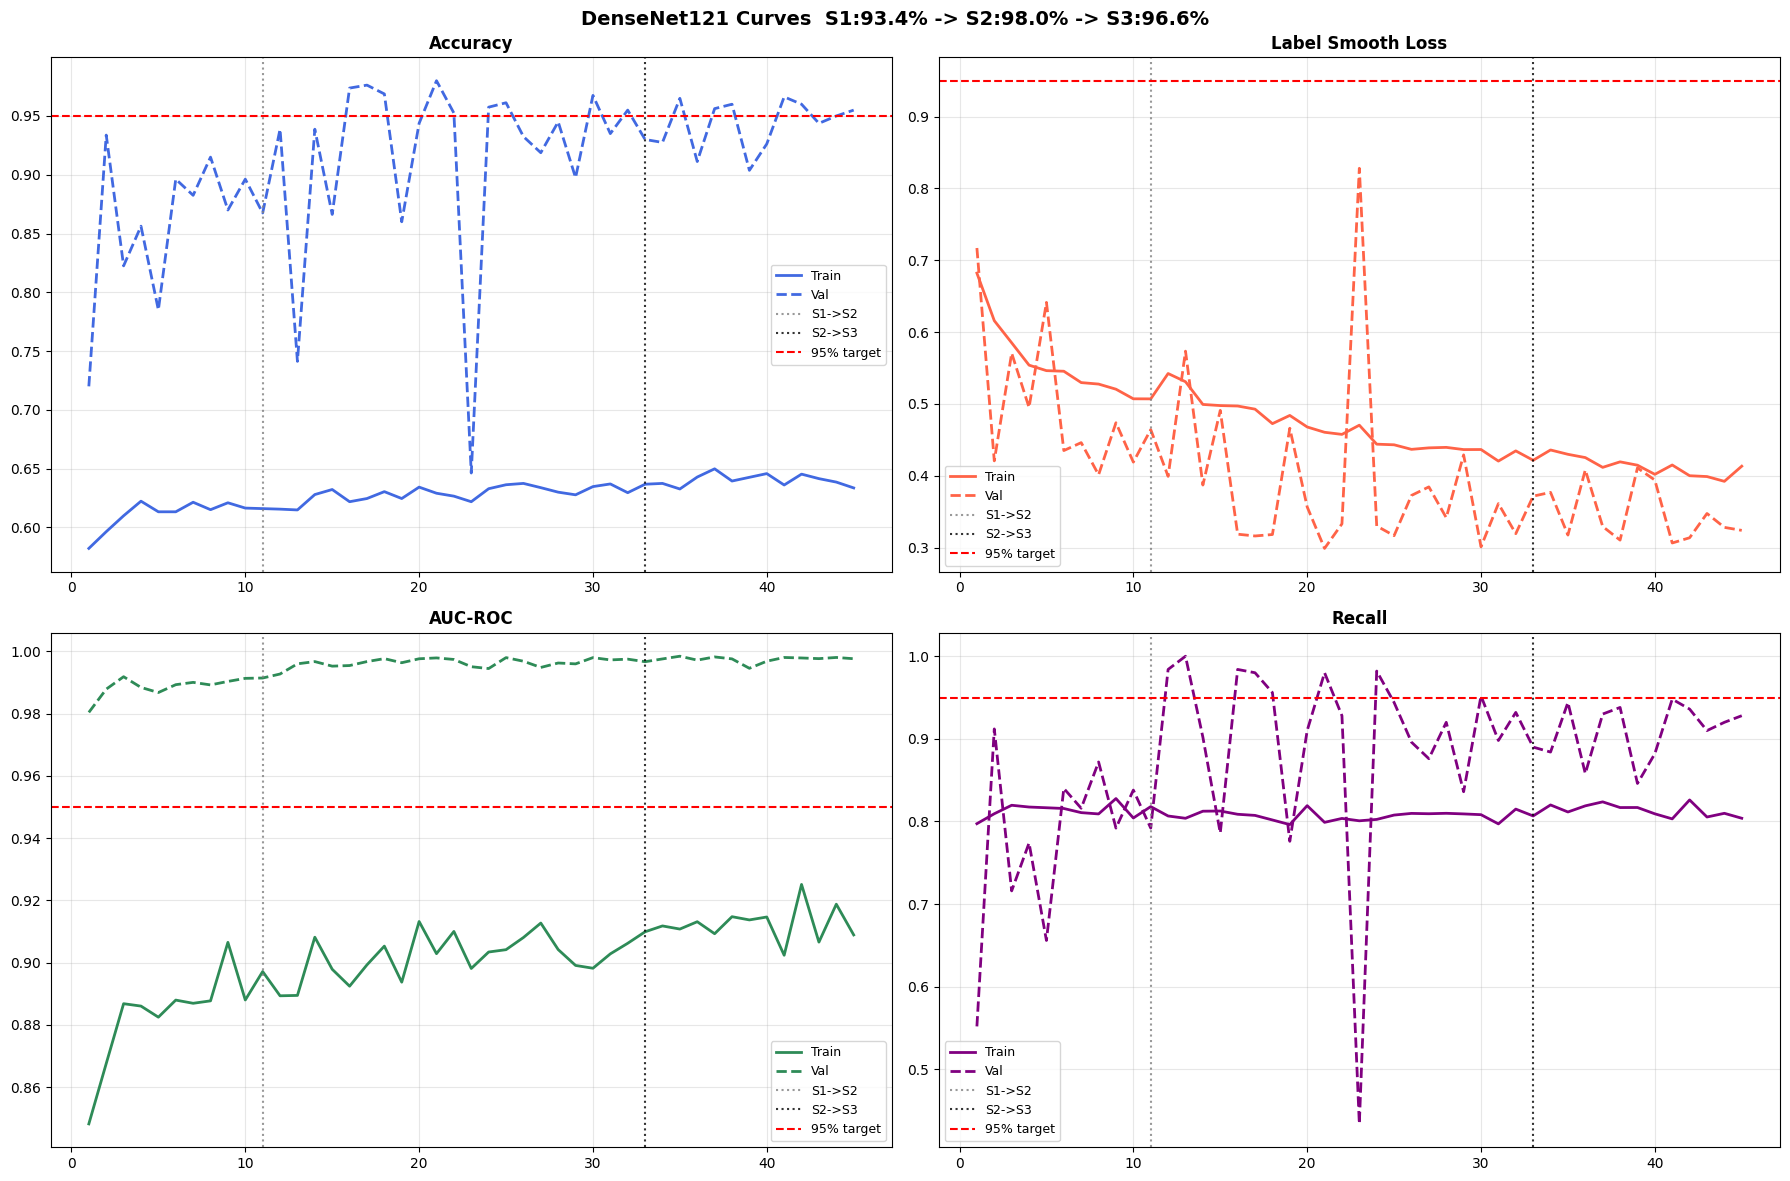

Saved: dn_curves.png
CELL 7 DONE -- DenseNet training complete!
Now open pneumonia_notebook.ipynb and run the updated Cell 8 for ensemble evaluation.


In [5]:
# ==================================================
# CELL 7 - STAGE 3: Full fine-tune + curves
# Saves: dn_stage3_best.h5 + dn_final.h5 + dn_curves.png
# If interrupted: re-run Cell 1 then this cell
# ==================================================
s2_path = os.path.join(OUTPUT_DIR,'models','dn_stage2.h5')
if os.path.exists(s2_path):
    dn_model.load_weights(s2_path)
    print('Loaded weights from dn_stage2.h5')

print('='*55)
print('DN STAGE 3 | ALL unfrozen, BN frozen | CosineDecay lr=1e-5')
print('='*55)

for l in dn_model.layers:
    l.trainable = False if isinstance(l, tf.keras.layers.BatchNormalization) else True
print(f'BN frozen | Trainable params: {sum([tf.size(w).numpy() for w in dn_model.trainable_weights]):,}')

S3_EPOCHS = 25
cosine_lr = tf.keras.experimental.CosineDecay(
    initial_learning_rate=1e-5, decay_steps=STEPS * S3_EPOCHS, alpha=1e-7)

dn_model.compile(optimizer=Adam(cosine_lr), loss=get_loss(0.0),
              metrics=['accuracy', AUC(name='auc'),
                       Precision(name='precision'), Recall(name='recall')])

h3 = dn_model.fit(
    train_gen_mix,
    epochs=S3_EPOCHS, steps_per_epoch=STEPS,
    validation_data=val_gen, validation_steps=VAL_STEPS,
    callbacks=[
        PureCheckpoint(os.path.join(OUTPUT_DIR,'models','dn_stage3_best.h5'),
                       monitor='val_auc', mode='max', verbose=1),
        EarlyStopping(monitor='val_auc', patience=10,
                      restore_best_weights=True, mode='max', verbose=0),
        ProgressBar(3, S3_EPOCHS, STEPS)
    ], verbose=0)

# Save alias dn_final.h5 to support any naming convention
shutil.copy2(os.path.join(OUTPUT_DIR,'models','dn_stage3_best.h5'),
             os.path.join(OUTPUT_DIR,'models','dn_final.h5'))
print('Saved: dn_stage3_best.h5 and dn_final.h5')

s3 = max(h3.history['val_accuracy'])
with open(os.path.join(OUTPUT_DIR,'models','dn_history_s3.json'),'w') as f:
    json.dump({k:[float(v) for v in vals] for k,vals in h3.history.items()}, f)
print(f'DN Stage 3:  acc={s3*100:.2f}%   auc={max(h3.history["val_auc"])*100:.2f}%')

# Training curves
with open(os.path.join(OUTPUT_DIR,'models','dn_history_s1.json')) as f: hs1=json.load(f)
with open(os.path.join(OUTPUT_DIR,'models','dn_history_s2.json')) as f: hs2=json.load(f)
hs3 = {k:[float(v) for v in vals] for k,vals in h3.history.items()}
s1v=max(hs1['val_accuracy']); s2v=max(hs2['val_accuracy'])
e1=len(hs1['accuracy']); e2=e1+len(hs2['accuracy'])
def combine(a,b,c,k): return a[k]+b[k]+c[k]

fig, axes = plt.subplots(2, 2, figsize=(18,12))
fig.suptitle(f'DenseNet121 Curves  S1:{s1v*100:.1f}% -> S2:{s2v*100:.1f}% -> S3:{s3*100:.1f}%',
             fontsize=14, fontweight='bold')
for ax,(tk,vk,title,col) in zip(axes.flat,[
        ('accuracy','val_accuracy','Accuracy','royalblue'),
        ('loss','val_loss','Binary Crossentropy Loss','tomato'),
        ('auc','val_auc','AUC-ROC','seagreen'),
        ('recall','val_recall','Recall','purple')]):
    t=combine(hs1,hs2,hs3,tk); v=combine(hs1,hs2,hs3,vk)
    ep=range(1,len(t)+1)
    ax.plot(ep,t,color=col,linewidth=2,label='Train')
    ax.plot(ep,v,color=col,linewidth=2,linestyle='--',label='Val')
    ax.axvline(x=e1,color='gray',linestyle=':',alpha=0.8,label='S1->S2')
    ax.axvline(x=e2,color='black',linestyle=':',alpha=0.8,label='S2->S3')
    ax.axhline(y=0.95,color='red',linestyle='--',linewidth=1.5,label='95% target')
    ax.set_title(title,fontsize=12,fontweight='bold')
    ax.legend(fontsize=9); ax.grid(True,alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR,'plots','dn_curves.png'),dpi=150,bbox_inches='tight')
plt.show()
print('Saved: dn_curves.png')
print('CELL 7 DONE -- DenseNet training complete!')
print('Proceed to inception.ipynb or pneumonia_notebook_final.ipynb Cell 8.')
